In [ ]:
#Install rivgraph from repo
!apt-get -qq install -y libgdal-dev gdal-bin > /dev/null
!pip install -q gdal=="$(gdal-config --version)" opencv-python-headless
!pip install -q --no-deps git+https://github.com/VeinsOfTheEarth/RivGraph.git
!git clone -q --depth 1 https://github.com/VeinsOfTheEarth/RivGraph.git
import rivgraph; print("ok", rivgraph.__file__)
!pip install loguru
import numpy as np, matplotlib.pyplot as plt, rasterio
from rasterio.transform import from_origin
from skimage import io, filters, morphology
from google.colab import files
import plotly.express as px
from rivgraph.classes import delta

In [ ]:
#Upload Input Image File
f = list(files.upload())[0]
im = io.imread(f)
g = im if im.ndim == 2 else np.float32(im[:,:,1]>im[:,:,2])
WATER_IS_BRIGHT = False  #Is water brigter or darker than land in the image
t = filters.threshold_otsu(g)
mask = (g > t) if WATER_IS_BRIGHT else (g < t)  #Make bitmask by thresholding
mask = morphology.remove_small_objects(mask, 64)
mask = morphology.remove_small_holes(mask, 64)

Saving 2020-10-28-00_00_2020-10-28-23_59_Sentinel-2_L2A_NDWI.tiff to 2020-10-28-00_00_2020-10-28-23_59_Sentinel-2_L2A_NDWI.tiff


In [ ]:
px.imshow(mask)

In [ ]:
with rasterio.open('mask.tif', 'w', driver='GTiff', height=mask.shape[0], width=mask.shape[1],
                   count=1, dtype='uint8', crs='EPSG:32645',
                   transform=from_origin(500000, 2500000, 1, 1)) as dst:
    dst.write(mask.astype('uint8'), 1)

#Make skeleton from mask
rn = delta('sundarbans', 'mask.tif', results_folder='results', verbose=True)
rn.skeletonize()
rn.compute_network()
rn.compute_distance_transform()
rn.compute_link_width_and_length()

---------- New Run ----------
Skeletonizing mask...
done with skeletonization.
Resolving links and nodes...
links and nodes have been resolved.
Computing distance transform...
distance transform done.
Computing link widths and lengths...
link widths and lengths computed.


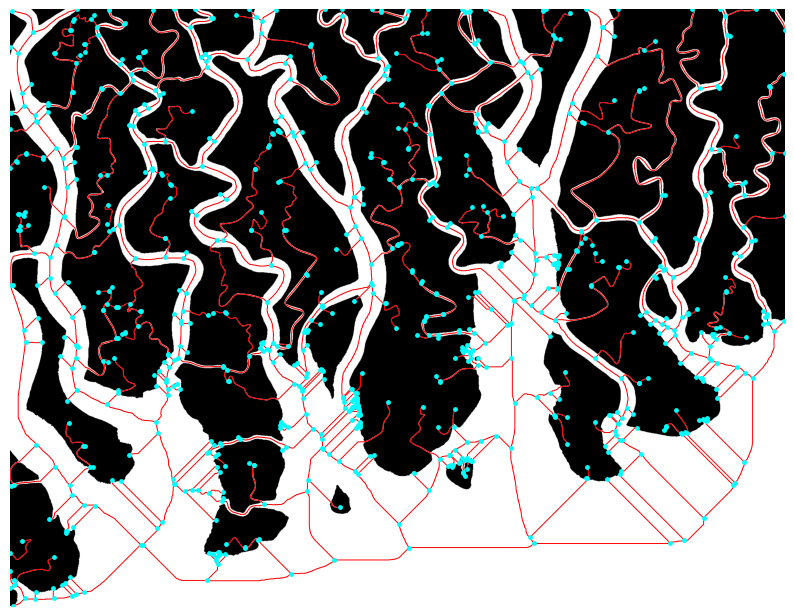

In [ ]:
#Plot network on mask
shape = rn.Imask.shape
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(rn.Imask, cmap='gray')
for idx in rn.links['idx']:
    r, c = np.unravel_index(idx, shape)
    ax.plot(c, r, 'r', lw=.7)
nr, nc = np.unravel_index(rn.nodes['idx'], shape)
ax.scatter(nc, nr, s=6, c='cyan', zorder=3)
ax.axis('off'); plt.show()

In [ ]:
import networkx as nx
import numpy as np

# 1. Create an undirected NetworkX graph from the rivgraph topology
G = nx.Graph()

# Add nodes with their properties (excluding spatial coordinates if not wanted, but we keep idx)
for i, node_idx in enumerate(rn.nodes['idx']):
    G.add_node(i, idx=node_idx)

# Add edges from links connecting the nodes
# 'conn' contains the 0-based indices of the nodes connected by each link
for i, conn in enumerate(rn.links['conn']):
    # conn is a list/array containing [node_u, node_v]
    G.add_edge(conn[0], conn[1], link_id=i)

print(f"NetworkX Graph created with {G.number_of_nodes()} nodes and {G.number_of_edges()} edges.")
shape = rn.Imask.shape
height, width = shape

NetworkX Graph created with 874 nodes and 898 edges.


In [ ]:
def simplify_degree_2_chains(graph):
    """
    Simplifies the graph in place by removing degree-2 nodes
    and connecting their neighbors directly.
    """
    g_simple = graph.copy()
    nodes_to_test = list(g_simple.nodes())

    for node in nodes_to_test:
        # Check if the node is still in the graph and has exactly degree 2
        if g_simple.has_node(node) and g_simple.degree(node) == 2:
            neighbors = list(g_simple.neighbors(node))
            u, v = neighbors[0], neighbors[1]

            # Prevent self-loops
            if u != v:
                # Connect the neighbors directly
                g_simple.add_edge(u, v)
                # Remove the degree-2 node
                g_simple.remove_node(node)

    return g_simple

In [ ]:
# 1. Extract the largest connected component of the original graph G
largest_cc = max(nx.connected_components(G), key=len)
G_cleaned = G.subgraph(largest_cc).copy()
print(f"Largest connected component selected: {G_cleaned.number_of_nodes()} nodes, {G_cleaned.number_of_edges()} edges (from {G.number_of_nodes()} original nodes)")

# 2. Identify middle 80% range along the y-axis
lower_y_threshold = height * 0.10
upper_y_threshold = height * 0.90
nr, nc = np.unravel_index(rn.nodes['idx'], shape)

# 3. Identify and remove degree-1 nodes in that middle y-region
nodes_to_remove = []
for node in G_cleaned.nodes():
    if G_cleaned.degree(node) == 1:
        node_row = nr[node]
        if lower_y_threshold <= node_row <= upper_y_threshold:
            nodes_to_remove.append(node)

G_cleaned.remove_nodes_from(nodes_to_remove)
print(f"Removed {len(nodes_to_remove)} degree-1 nodes from the middle 80% of the y-axis.")

# 4. Remove any resulting 0-degree (isolated) nodes
isolated_nodes = [node for node in G_cleaned.nodes() if G_cleaned.degree(node) == 0]
G_cleaned.remove_nodes_from(isolated_nodes)
print(f"Removed {len(isolated_nodes)} resulting isolated (degree 0) nodes.")

# 5. Perform the degree-2 chain simplification
G_simplified = simplify_degree_2_chains(G_cleaned)
G_simplified = simplify_degree_2_chains(G_simplified)
print(f"\nFinal Cleaned Graph: {G_cleaned.number_of_nodes()} nodes, {G_cleaned.number_of_edges()} edges")
print(f"Final Simplified Graph: {G_simplified.number_of_nodes()} nodes, {G_simplified.number_of_edges()} edges")

Largest connected component selected: 848 nodes, 881 edges (from 874 original nodes)
Removed 319 degree-1 nodes from the middle 80% of the y-axis.
Removed 0 resulting isolated (degree 0) nodes.

Final Cleaned Graph: 529 nodes, 562 edges
Final Simplified Graph: 315 nodes, 347 edges


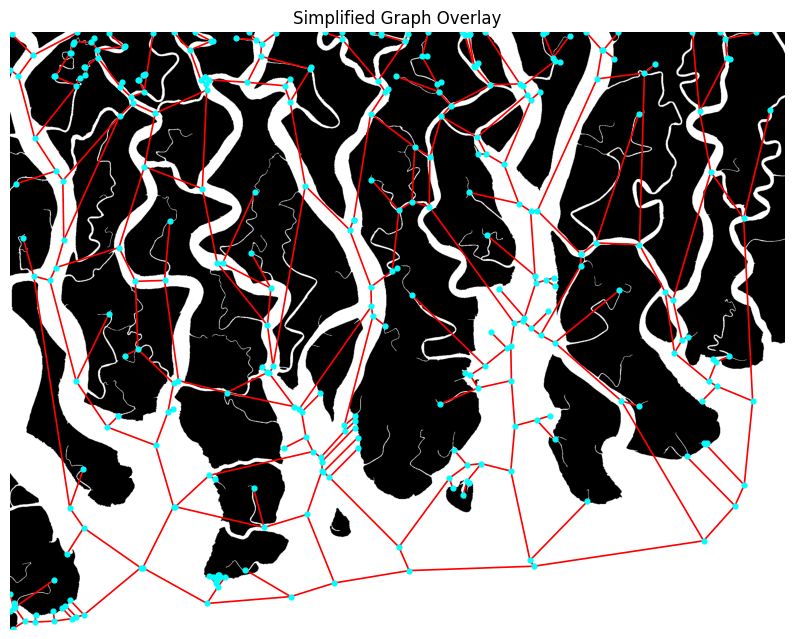

In [ ]:

nr, nc = np.unravel_index(rn.nodes['idx'], shape)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(rn.Imask, cmap='gray')

for u, v in G_simplified.edges():
    r_coords = [nr[u], nr[v]]
    c_coords = [nc[u], nc[v]]
    ax.plot(c_coords, r_coords, 'r', lw=1.2, zorder=2)

node_indices = list(G_simplified.nodes())
node_rows = nr[node_indices]
node_cols = nc[node_indices]
ax.scatter(node_cols, node_rows, s=12, c='cyan', zorder=3)

ax.set_title("Simplified Graph Overlay")
ax.axis('off')
plt.show()